PROBLEM STATEMENT:

To analyze laptop prices on Flipkart based on key hardware specifications such as RAM, storage, processor, display size, brand, generation and warranty, and to identify which factors have the most influence on laptop pricing.

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
product_name = []
product_price = []
product_storage = []
product_ram = []
product_display = []
product_processor = []
product_warranty = []
operating_system = []
product_brand = []
product_generation = []



In [ ]:
for i in range(1, 21):  # 20 pages × ~20 laptops = ~400

    url = f"https://www.flipkart.com/search?q=laptops&page={i}"

    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:126.0) Gecko/20100101 Firefox/126.0',
        'Accept-Encoding': 'gzip, deflate, br, zstd'
    }

    response = requests.get(url, headers=headers)
    print(f"Status_code page {i}:", response.status_code)

    soup = BeautifulSoup(response.text, "html.parser")


Status_code page 1: 200
Status_code page 2: 200
Status_code page 3: 200
Status_code page 4: 200
Status_code page 5: 200
Status_code page 6: 200
Status_code page 7: 200
Status_code page 8: 200
Status_code page 9: 200
Status_code page 10: 200
Status_code page 11: 200
Status_code page 12: 200
Status_code page 13: 200
Status_code page 14: 200
Status_code page 15: 200
Status_code page 16: 200
Status_code page 17: 200
Status_code page 18: 200
Status_code page 19: 200
Status_code page 20: 200


In [ ]:
import re

# ---------- Product Name, Brand, Generation ----------
for i in soup.find_all("div", class_="RG5Slk"):
    text = i.text
    product_name.append(text)
    product_brand.append(text.split()[0])

    intel_gen = re.search(r'(\d{1,2})(st|nd|rd|th)?\sGen', text)
    amd_gen = re.search(r'Ryzen\s[3579]\s(\d{4})', text)

    if intel_gen:
        product_generation.append(intel_gen.group(1) + "th Gen")
    elif "Core Ultra" in text:
        product_generation.append("Core Ultra Series")
    elif amd_gen:
        product_generation.append(amd_gen.group(1)[0] + "000 Series")
    elif "Snapdragon" in text:
        product_generation.append("Qualcomm")
    elif "MediaTek" in text:
        product_generation.append("MediaTek")
    else:
        product_generation.append("Other")

# ---------- Product Price ----------
for i in soup.find_all("div", class_="hZ3P6w DeU9vF"):
    product_price.append(i.text)

# ---------- Product Features ----------
for i in soup.find_all("li", class_="DTBslk"):
    if "RAM" in i.text:
        product_ram.append(i.text)
    elif "Display" in i.text:
        product_display.append(i.text)
    elif "Warranty" in i.text:
        product_warranty.append(i.text)
    elif "Processor" in i.text:
        product_processor.append(i.text)
    elif "SSD" in i.text or "HDD" in i.text or "EMMC" in i.text or "Storage" in i.text:
        product_storage.append(i.text)
    elif "Windows 11" in i.text or "Windows 10" in i.text or "Chrome" in i.text:
        operating_system.append(i.text)


In [ ]:
print("product_name:", len(product_name))
print("product_price:", len(product_price))
print("product_ram:", len(product_ram))
print("product_display:", len(product_display))
print("product_storage:", len(product_storage))
print("product_processor:", len(product_processor))
print("product_warranty:", len(product_warranty))
print("operating_system:", len(operating_system))
print("product_brand:", len(product_brand))
print("product_generation:", len(product_generation))


product_name: 456
product_price: 456
product_ram: 456
product_display: 456
product_storage: 437
product_processor: 456
product_warranty: 418
operating_system: 475
product_brand: 456
product_generation: 456


In [ ]:
min_len = min(
    len(product_name),
    len(product_price),
    len(product_ram),
    len(product_display),
    len(product_storage),
    len(product_processor),
    len(product_warranty),
    len(operating_system),
    len(product_brand),
    len(product_generation)
)

In [ ]:
df = pd.DataFrame({
        "product_name": product_name[:min_len],
        "product_price": product_price[:min_len],
        "product_ram": product_ram[:min_len],
        "product_display": product_display[:min_len],
        "product_storage": product_storage[:min_len],
        "product_processor": product_processor[:min_len],
        "product_warranty": product_warranty[:min_len],
        "operating_system": operating_system[:min_len],
        "product_brand": product_brand[:min_len],
        "product_generation": product_generation[:min_len]
})

In [143]:
df['operating_system'] = df['operating_system'].str.extract(r'(Windows 11|Windows 10|Chrome OS)')
df['product_warranty'] = df['product_warranty'].astype(str)
df['product_warranty'] = df['product_warranty'].str.extract(r'(\d+\sYear)')




In [ ]:
df

,product_name,product_price,product_ram,product_display,product_storage,product_processor,product_warranty,operating_system,product_brand,product_generation
0,Samsung Galaxy Book4 Edge Series Copilot AI-PC...,"₹59,550",16 GB LPDDR5X RAM,39.62 cm (15.6 Inch) Display,512 GB SSD,Qualcomm Snapdragon X Processor,1 Year,Windows 11,Samsung,Qualcomm
1,Acer Aspire 15 AMD Ryzen 5 Hexa Core 7430U - (...,"₹34,990",16 GB DDR4 RAM,39.62 cm (15.6 Inch) Display,512 GB SSD,AMD Ryzen 5 Hexa Core Processor,1 Year,Windows 11,Acer,Other
2,ASUS Vivobook S14 (2025)(i5 14th Gen) with Off...,"₹64,190",16 GB DDR5 RAM,35.56 cm (14 Inch) Display,512 GB SSD,Intel Core 5 Processor,1 Year,Windows 11,ASUS,14th Gen
3,ASUS Vivobook S14 Flip (2025) with Office 2024...,"₹63,632",16 GB DDR4 RAM,35.56 cm (14 Inch) Touchscreen Display,512 GB SSD,Intel Core i5 Processor (13th Gen),1 Year,Windows 11,ASUS,13th Gen
4,HP 15 Intel Core 3 100U - (8 GB/512 GB SSD/Win...,"₹37,990",8 GB DDR4 RAM,39.62 cm (15.6 Inch) Display,512 GB SSD,Intel Core 3 Processor,1 Year,Windows 11,HP,Other
...,...,...,...,...,...,...,...,...,...,...
413,Lenovo IdeaPad Slim 3 Next Gen AI PC WUXGA IPS...,"₹50,990",16 GB LPDDR5X RAM,38.86 cm (15.3 Inch) Display,512 GB SSD,Qualcomm Snapdragon X Processor,1 Year,Windows 11,Lenovo,Qualcomm
414,Lenovo ThinkBook 16 G6 ABP AMD Ryzen 7 Octa Co...,"₹55,000",16 GB DDR4 RAM,40.64 cm (16 Inch) Display,512 GB SSD,AMD Ryzen 7 Octa Core Processor,1 Year,Windows 11,Lenovo,Other
415,HP Pavilion AMD Ryzen 5 Dual Core 5500U - (8 G...,"₹51,990",8 GB DDR4 RAM,39.62 cm (15.6 Inch) Display,512 GB SSD,AMD Ryzen 5 Dual Core Processor,1 Year,Windows 11,HP,Other
416,MSI Pulse GL66 Intel Core i7 11th Gen 11800H -...,"₹1,22,990",16 GB DDR4 RAM,39.62 cm (15.6 Inches) Display,512 GB SSD,Intel Core i7 Processor (11th Gen),1 Year,Windows 11,MSI,11th Gen


In [ ]:
df.product_price = [col.replace("₹","").replace(",","") for col in df.product_price]

In [ ]:
df.product_price = df.product_price.astype(int)

In [ ]:
df.product_price

,product_price
0,59550
1,34990
2,64190
3,63632
4,37990
...,...
413,50990
414,55000
415,51990
416,122990


In [ ]:
# Export dataframe to CSV
df.to_csv("flipkart_laptops.csv", index=False)

print("CSV file exported successfully")


CSV file exported successfully


In [ ]:
import pandas as pd

# Read CSV file
df = pd.read_csv("flipkart_laptops.csv")

# 1 Number of features (columns)
print("Number of Columns:", df.shape[1])

# 2️ Number of observations (rows)
print("Number of Rows:", df.shape[0])

# 3️ Data types of each column
print("\nData Types:")
print(df.dtypes)

# 4️ Missing values count
print("\nMissing Values:")
print(df.isnull().sum())


Number of Columns: 10
Number of Rows: 418

Data Types:
product_name          object
product_price          int64
product_ram           object
product_display       object
product_storage       object
product_processor     object
product_warranty      object
operating_system      object
product_brand         object
product_generation    object
dtype: object

Missing Values:
product_name           0
product_price          0
product_ram            0
product_display        0
product_storage        0
product_processor      0
product_warranty       0
operating_system      16
product_brand          0
product_generation     0
dtype: int64


In [ ]:
#Convert columns to STRING first
df['product_price'] = df['product_price'].astype(str)
df['product_ram'] = df['product_ram'].astype(str)
df['product_storage'] = df['product_storage'].astype(str)
df['product_display'] = df['product_display'].astype(str)


In [ ]:
#Use RAW STRINGS for regex (r'')
df['product_price'] = df['product_price'].str.replace('₹', '', regex=False).str.replace(',', '', regex=False)

df['product_ram'] = df['product_ram'].str.extract(r'(\d+)')
df['product_storage'] = df['product_storage'].str.extract(r'(\d+)')
df['product_display'] = df['product_display'].str.extract(r'([\d.]+)')


In [ ]:
#Convert to NUMERIC
df['product_price'] = pd.to_numeric(df['product_price'], errors='coerce')
df['product_ram'] = pd.to_numeric(df['product_ram'], errors='coerce')
df['product_storage'] = pd.to_numeric(df['product_storage'], errors='coerce')
df['product_display'] = pd.to_numeric(df['product_display'], errors='coerce')


In [ ]:
df['operating_system'] = df['operating_system'].fillna(df['operating_system'].mode()[0])



In [ ]:
df.columns


Index(['product_name', 'product_price', 'product_ram', 'product_display',
       'product_storage', 'product_processor', 'product_warranty',
       'operating_system', 'product_brand', 'product_generation'],
      dtype='object')

In [ ]:
df.dtypes


,0
product_name,object
product_price,int64
product_ram,int64
product_display,float64
product_storage,int64
product_processor,object
product_warranty,object
operating_system,object
product_brand,object
product_generation,object


In [142]:
df["product_generation"] = df["product_generation"].fillna(df["product_generation"].mode()[0])


In [133]:
df.loc[df["product_processor"].str.contains("Ryzen", na=False),
       "product_generation"] = "AMD Series"

df.loc[df["product_processor"].str.contains("Snapdragon", na=False),
       "product_generation"] = "Qualcomm"


In [ ]:
df.isnull().sum()


,0
product_name,0
product_price,0
product_ram,0
product_display,0
product_storage,0
product_processor,0
product_warranty,0
operating_system,0
product_brand,0
product_generation,0


In [141]:
df.to_csv("flipkart_laptops.csv", index=False)

print("CSV file exported successfully")

CSV file exported successfully


In [140]:
df

,product_name,product_price,product_ram,product_display,product_storage,product_processor,product_warranty,operating_system,product_brand,product_generation
0,Samsung Galaxy Book4 Edge Series Copilot AI-PC...,59550,16,39.62,512,Qualcomm Snapdragon X Processor,1 Year,Windows 11,Samsung,Qualcomm
1,Acer Aspire 15 AMD Ryzen 5 Hexa Core 7430U - (...,34990,16,39.62,512,AMD Ryzen 5 Hexa Core Processor,1 Year,Windows 11,Acer,AMD Series
2,ASUS Vivobook S14 (2025)(i5 14th Gen) with Off...,64190,16,35.56,512,Intel Core 5 Processor,1 Year,Windows 11,ASUS,14th Gen
3,ASUS Vivobook S14 Flip (2025) with Office 2024...,63632,16,35.56,512,Intel Core i5 Processor (13th Gen),1 Year,Windows 11,ASUS,13th Gen
4,HP 15 Intel Core 3 100U - (8 GB/512 GB SSD/Win...,37990,8,39.62,512,Intel Core 3 Processor,1 Year,Windows 11,HP,Other
...,...,...,...,...,...,...,...,...,...,...
413,Lenovo IdeaPad Slim 3 Next Gen AI PC WUXGA IPS...,50990,16,38.86,512,Qualcomm Snapdragon X Processor,1 Year,Windows 11,Lenovo,Qualcomm
414,Lenovo ThinkBook 16 G6 ABP AMD Ryzen 7 Octa Co...,55000,16,40.64,512,AMD Ryzen 7 Octa Core Processor,1 Year,Windows 11,Lenovo,AMD Series
415,HP Pavilion AMD Ryzen 5 Dual Core 5500U - (8 G...,51990,8,39.62,512,AMD Ryzen 5 Dual Core Processor,1 Year,Windows 11,HP,AMD Series
416,MSI Pulse GL66 Intel Core i7 11th Gen 11800H -...,122990,16,39.62,512,Intel Core i7 Processor (11th Gen),1 Year,Windows 11,MSI,11th Gen


DATA ANALYSIS AND VISUALIZATION

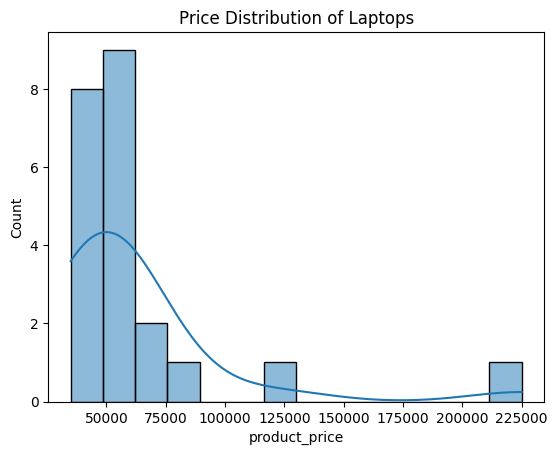

In [ ]:
#Price Distribution
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['product_price'], kde=True)
plt.title("Price Distribution of Laptops")
plt.show()


Most laptops are priced between 30,000 to 80,000 INR.

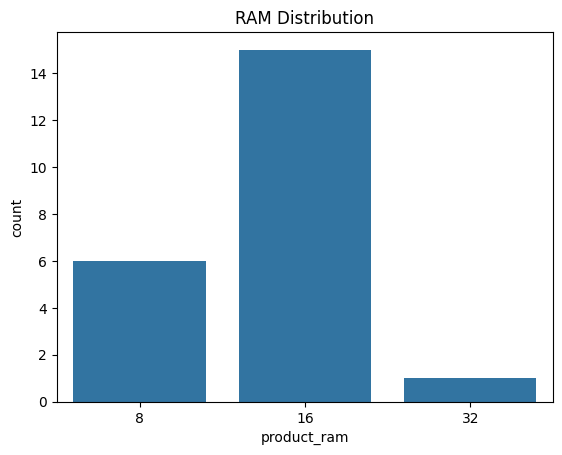

In [ ]:
#RAM Distribution
sns.countplot(x=df['product_ram'])
plt.title("RAM Distribution")
plt.show()


Majority of laptops have 8GB or 16GB RAM

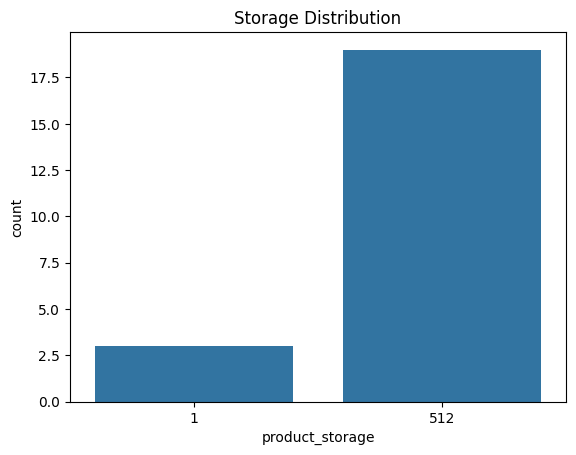

In [ ]:
#Storage Distribution
sns.countplot(x=df['product_storage'])
plt.title("Storage Distribution")
plt.show()


Most laptops come with 512GB storage.

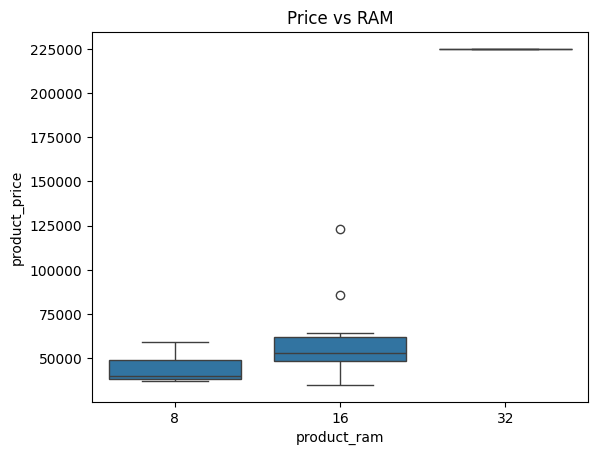

In [ ]:
#Price vs RAM
sns.boxplot(x='product_ram', y='product_price', data=df)
plt.title("Price vs RAM")
plt.show()


Price increases with higher RAM.

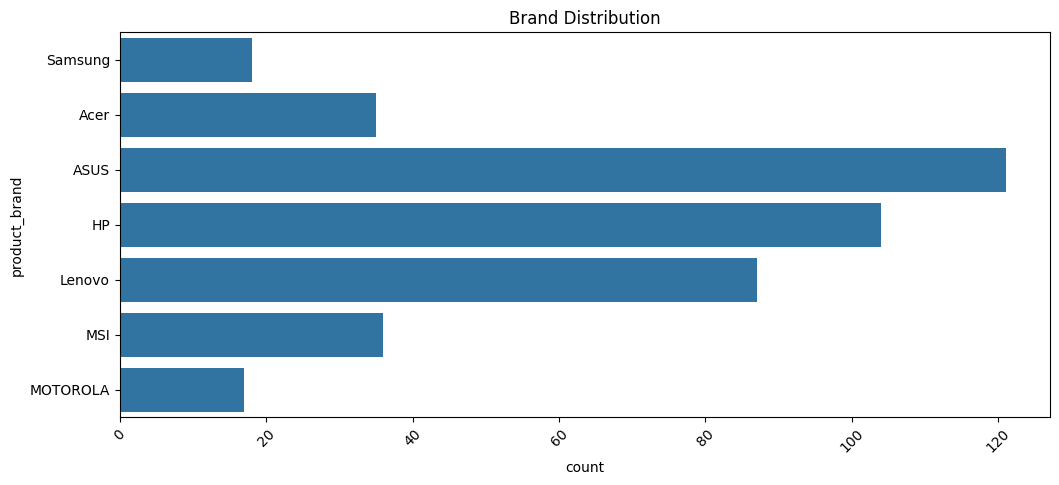

In [138]:
plt.figure(figsize=(12,5))
sns.countplot(df['product_brand'])
plt.title("Brand Distribution")
plt.xticks(rotation=45)
plt.show()


Most common brands are ASUS, HP, Lenovo.

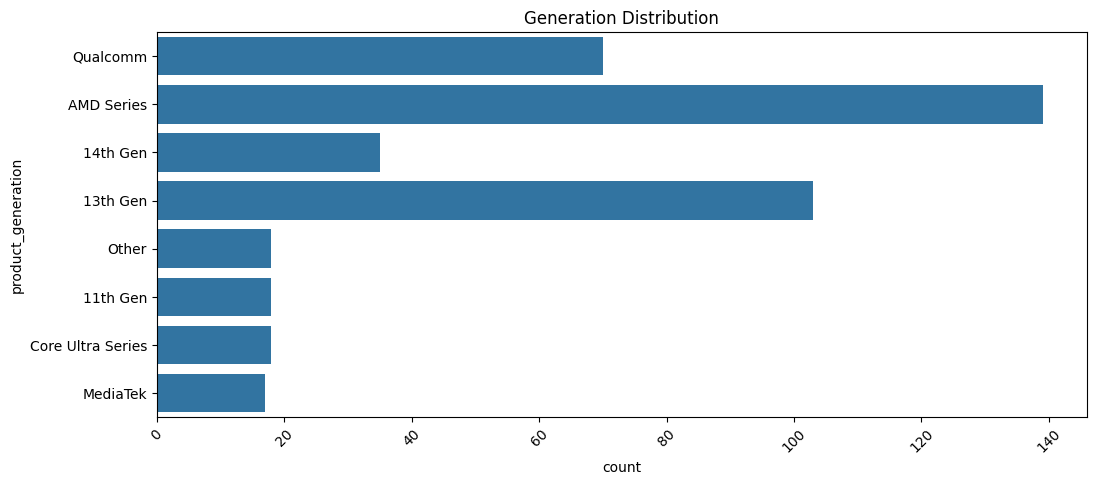

In [139]:
plt.figure(figsize=(12,5))
sns.countplot(df['product_generation'])
plt.title("Generation Distribution")
plt.xticks(rotation=45)
plt.show()


Most laptops belong to 13th Gen and 14th Gen.

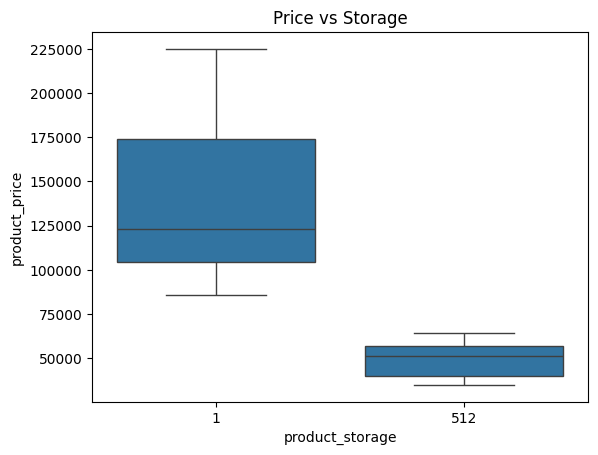

In [ ]:
#price vs storage
sns.boxplot(x='product_storage', y='product_price', data=df)
plt.title("Price vs Storage")
plt.show()


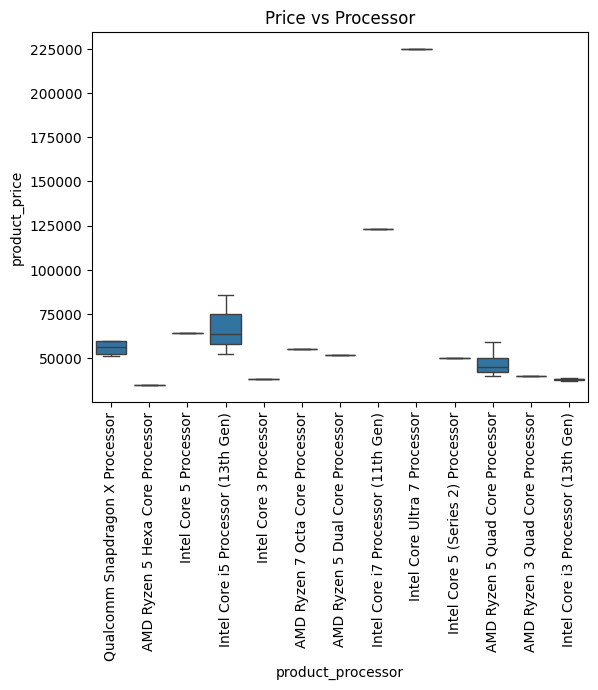

In [ ]:
#Price vs Storage
sns.boxplot(x='product_processor', y='product_price', data=df)
plt.xticks(rotation=90)
plt.title("Price vs Processor")
plt.show()


Interpretation:

Intel i7 and Core Ultra are expensive.

i5 is mid-range, and i3 or Celeron are cheaper.

AMD Ryzen 7 is usually high price but depends on model.

Processor is a major factor affecting price.

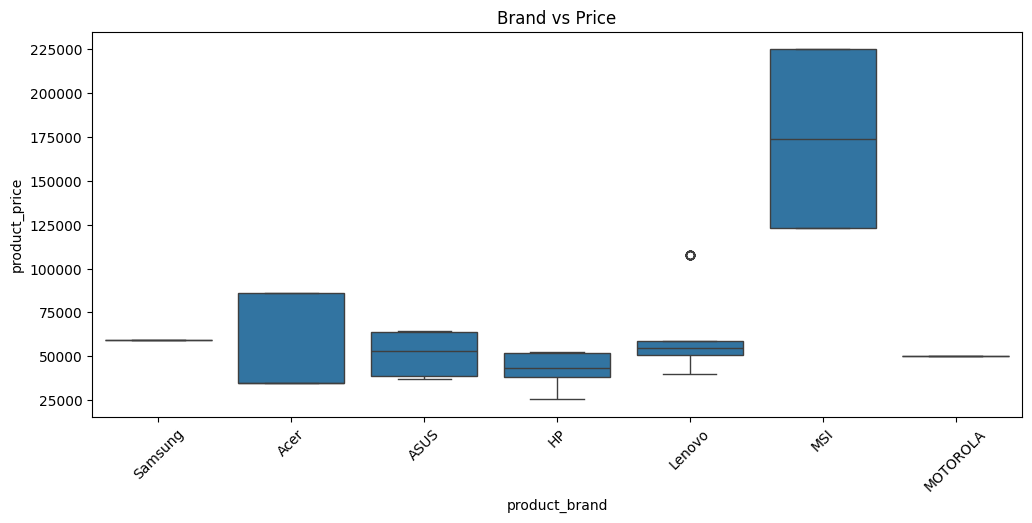

In [134]:
plt.figure(figsize=(12,5))
sns.boxplot(x='product_brand', y='product_price', data=df)
plt.title("Brand vs Price")
plt.xticks(rotation=45)
plt.show()


Interpretation:

Some brands like MSI, Lenovo LOQ, and Apple (if present) show higher prices because they are gaming or premium laptops.

Brands like HP, Acer, and Lenovo have more mid-range priced laptops.

Samsung & Motorola have fewer models but are mostly mid-range.

Brand affects price because brand value, after-sales support, and build quality differ.

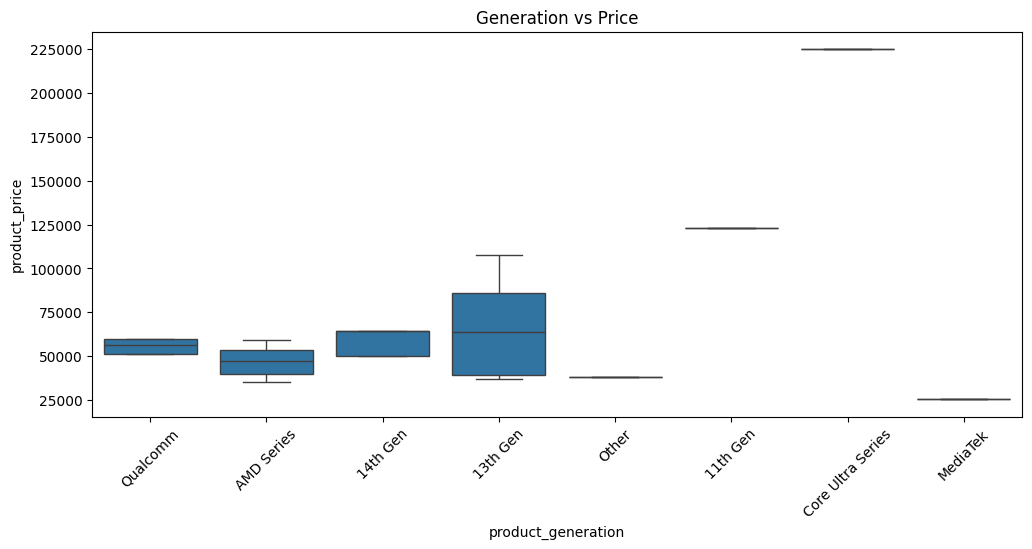

In [135]:
plt.figure(figsize=(12,5))
sns.boxplot(x='product_generation', y='product_price', data=df)
plt.title("Generation vs Price")
plt.xticks(rotation=45)
plt.show()


Interpretation:

Newer generations like 13th Gen and 14th Gen usually cost higher.

Older generations like 11th Gen are cheaper.

Core Ultra series may not be the highest because they are more focused on efficiency and not always gaming.

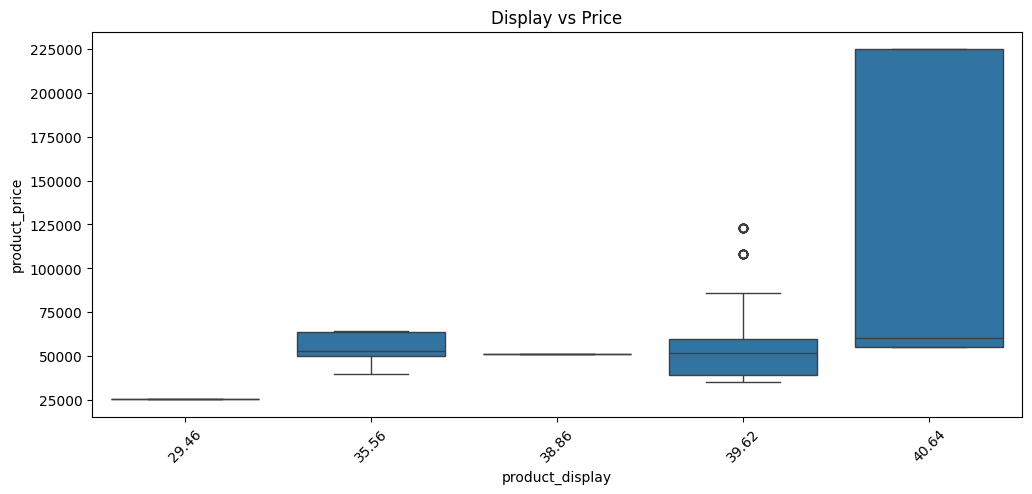

In [136]:
plt.figure(figsize=(12,5))
sns.boxplot(x='product_display', y='product_price', data=df)
plt.title("Display vs Price")
plt.xticks(rotation=45)
plt.show()


Interpretation:

Bigger display size like 16-inch or 15.6-inch usually costs more.

Smaller displays like 14-inch or 13-inch are cheaper.

Touchscreen and OLED displays are expensive.

Display size and type influence price.

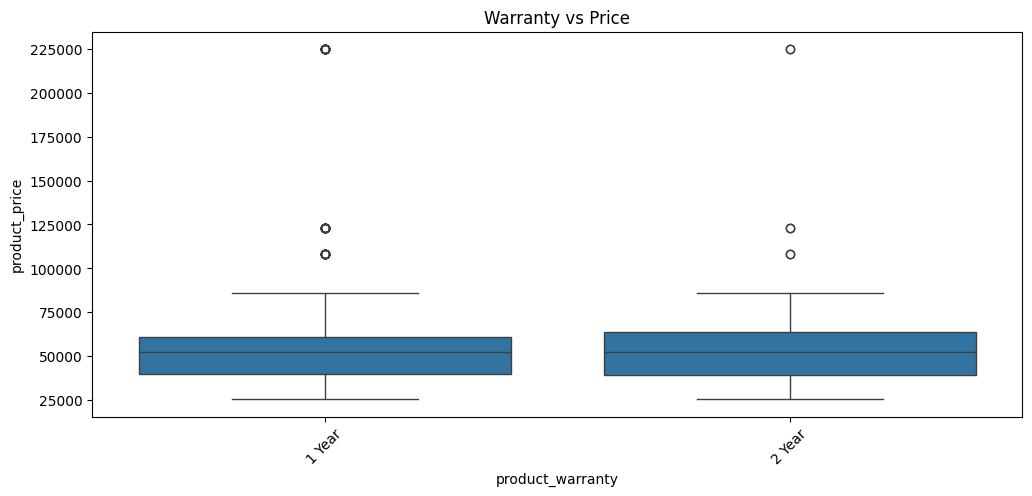

In [137]:
plt.figure(figsize=(12,5))
sns.boxplot(x='product_warranty', y='product_price', data=df)
plt.title("Warranty vs Price")
plt.xticks(rotation=45)
plt.show()


Interpretation:

Longer warranty (2 years or more) usually has higher price.

1-year warranty laptops are cheaper.

Warranty affects price because more warranty means higher after-sales cost for the brand.

In [ ]:
pd.crosstab(df['product_brand'], df['product_generation'])


product_generation,11th Gen,13th Gen,14th Gen,AMD Series,Core Ultra Series,Other,Qualcomm
product_brand,,,,,,,
ASUS,0,3,1,1,0,0,2
Acer,0,1,0,1,0,0,0
HP,0,1,0,3,0,1,0
Lenovo,0,0,0,3,0,0,1
MOTOROLA,0,0,1,0,0,0,0
MSI,1,0,0,0,1,0,0
Samsung,0,0,0,0,0,0,1


Interpretation:

Shows which brand uses which processor generation more.

For example:

MSI mostly has 11th Gen

ASUS has 13th Gen

HP has mix of 13th & AMD

Helps to understand brand strategy.

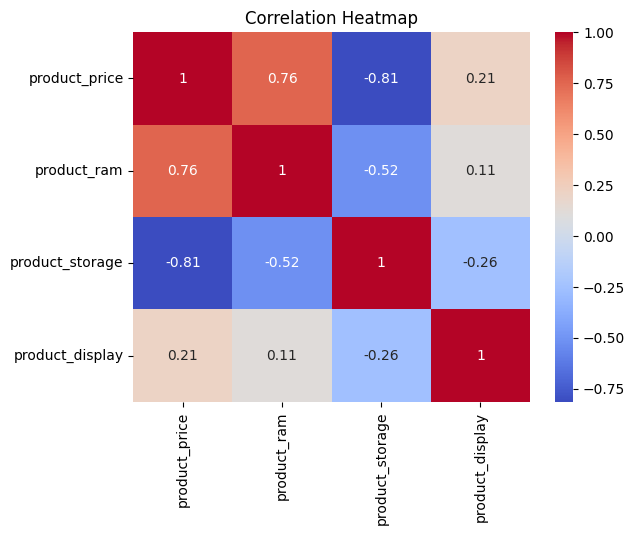

In [ ]:
sns.heatmap(df[['product_price','product_ram','product_storage','product_display']].corr(),
            annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()



Interpretation:

Price has strong positive correlation with RAM, Storage and Processor generation.

If RAM and Storage increase, price increases.

Correlation shows which features affect price most.

Conclusion:

Processor, RAM, and Storage are the major factors affecting laptop price.

Brand and Generation also influence price, as premium brands and newer generations cost more.

Display size and warranty also contribute to price increase.

Based on analysis, the highest price laptops are mostly Intel i7 / Core Ultra / Ryzen 7, with 16GB+ RAM and 512GB+ storage.